# Экзаменационная задача №17. Подготовка и защита бюджета ИТ-проекта (обоснование бюджета BI)

**Дисциплина:** Экономика информатизации, лекция №18
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №17: ПОДГОТОВКА И ЗАЩИТА БЮДЖЕТА ИТ-ПРОЕКТА (ОБОСНОВАНИЕ БЮДЖЕТА BI)
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №18)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Организация хочет внедрить BI-систему: витрина данных, дашборды, отчёты, которые сотрудники строят сами.
Затраты 50 млн руб., ожидаемая экономия 15 млн руб. в год. Нужно не только посчитать показатели, но и **подготовить
и защитить бюджет** перед финансовым директором, руководством, ИТ-службой и пользователями.

**Цель:** посчитать ROI, NPV и срок окупаемости, подготовить структуру презентации, аргументы для каждой стороны
и способы согласовать бюджет.

Тема лекции №18: обоснование ИТ-бюджета, ROI, NPV, срок окупаемости, работа с заинтересованными сторонами,
финансирование по этапам, анализ чувствительности как инструмент защиты бюджета.

## 2. Исходные данные

In [2]:
invest = 50.0         # затраты на внедрение, млн руб. (год 0)
saving = 15.0         # ожидаемая экономия, млн руб./год
H, r = 5, 0.10        # горизонт и ставка — ДОПУЩЕНИЕ (в условии не заданы)
# Структура бюджета (допущение — типовое распределение для BI-проекта)
budget = pd.Series({"Лицензии BI-платформы": 14.0, "Хранилище данных и интеграции (ETL)": 15.0,
                    "Разработка дашбордов и моделей": 9.0, "Оборудование / облачная инфраструктура": 4.0,
                    "Обучение пользователей": 3.0, "Управление проектом": 2.5, "Резерв на риски (5%)": 2.5}, name="млн руб.")
assert abs(budget.sum() - invest) < 1e-9
budget.to_frame()

,млн руб.
Лицензии BI-платформы,14.00
Хранилище данных и интеграции (ETL),15.00
Разработка дашбордов и моделей,9.00
Оборудование / облачная инфраструктура,4.00
Обучение пользователей,3.00
Управление проектом,2.50
Резерв на риски (5%),2.50


**Допущения:**
- Срок и ставка в условии **не даны**. Берём 5 лет (обычный срок жизни BI до модернизации) и 10 %
  (как в задаче лекции №20 про тот же проект). Как результат зависит от обоих параметров, показано ниже.
- Не сказано, вычтены ли из 15 млн руб. **ежегодные затраты на владение** BI (поддержка лицензий около 20 % в год,
  администрирование). В основном расчёте 15 млн руб. считаем чистой экономией, вариант с затратами 3 млн руб. в год
  в анализе рисков.
- 50 млн руб. тратим разово в году 0, экономия с 1-го года (на деле первые месяцы уходят на внедрение, это учтено
  в сценарии «задержка эффекта»). Налоги не учитываем (бюджетная оценка до налогов).

## 3. Математическая модель

$$ROI = \frac{\sum_{t=1}^{H} S_t - I}{I},\qquad NPV = -I + \sum_{t=1}^{H}\frac{S_t}{(1+r)^t},\qquad PP = \frac{I}{S},\qquad DPP: \sum_{t\le DPP}\frac{S_t}{(1+r)^t} = I$$
Дополнительно IRR и индекс доходности $PI = \sum PV(S_t)/I$. Безубыточная экономия: $S^* = I / \text{аннуитет}(r,H)$.

## 4. Реализация расчёта
### 4.1. Показатели эффективности

In [3]:
def flows(I=invest, S=saving, years=H, opex=0.0, delay=0.0):
    """Денежный поток: инвестиция в году 0, экономия по годам (delay — доля потери эффекта в 1-м году)."""
    cf = [-I] + [S - opex] * years
    cf[1] = S * (1 - delay) - opex
    return np.array(cf)

cf = flows()
res = {"ROI за 5 лет": f"{(cf[1:].sum() - invest) / invest:.0%}", "NPV (10%), млн руб.": f"{npv(cf, r):.2f}",
       "IRR": f"{irr(cf):.1%}", "Простой срок окупаемости": f"{payback_period(cf):.2f} г.",
       "Дисконт. срок окупаемости": f"{discounted_payback_period(cf, r):.2f} г.",
       "Индекс доходности PI": f"{present_values(cf, r)[1:].sum() / invest:.2f}",
       "Безубыточная экономия S*": f"{invest / annuity_factor(r, H):.2f} млн руб./год"}
tbl = pd.DataFrame({"Год": range(H + 1), "CF": cf, "PV": present_values(cf, r)})
tbl["Накопл. CF"] = tbl["CF"].cumsum(); tbl["Накопл. PV"] = tbl["PV"].cumsum()
display(tbl.set_index("Год").round(2))
pd.Series(res, name="Значение").to_frame()

,CF,PV,Накопл. CF,Накопл. PV
Год,,,,
0,-50.00,-50.00,-50.00,-50.00
1,15.00,13.64,-35.00,-36.36
2,15.00,12.40,-20.00,-23.97
3,15.00,11.27,-5.00,-12.70
4,15.00,10.25,10.00,-2.45
5,15.00,9.31,25.00,6.86


,Значение
ROI за 5 лет,50%
"NPV (10%), млн руб.",6.86
IRR,15.2%
Простой срок окупаемости,3.33 г.
Дисконт. срок окупаемости,4.26 г.
Индекс доходности PI,1.14
Безубыточная экономия S*,13.19 млн руб./год


### 4.2. Сценарии и чувствительность (аргументы для защиты)

In [4]:
scen = {"Базовый": {}, "Экономия −30% (10,5)": {"S": 10.5}, "Экономия +20% (18)": {"S": 18},
        "Затраты +20% (60)": {"I": 60}, "Текущие затраты 3 млн/год": {"opex": 3.0},
        "Эффект 1-го года −50% (задержка)": {"delay": 0.5}, "Горизонт 3 года": {"years": 3}, "Горизонт 7 лет": {"years": 7}}
sc = pd.DataFrame([{"Сценарий": k, "NPV (10%)": npv(flows(**v), r), "ROI": (flows(**v)[1:].sum() - flows(**v)[0] * -1) / -flows(**v)[0],
                    "Окупаемость, лет": payback_period(flows(**v))} for k, v in scen.items()]).set_index("Сценарий")
sc["NPV при 15%"] = [npv(flows(**v), 0.15) for v in scen.values()]
sc["Вывод"] = np.where(sc["NPV (10%)"] > 0, "эффективен", "не окупается")
sc.round(2)

,NPV (10%),ROI,"Окупаемость, лет",NPV при 15%,Вывод
Сценарий,,,,,
Базовый,6.86,0.50,3.33,0.28,эффективен
"Экономия −30% (10,5)",-10.20,0.05,4.76,-14.80,не окупается
Экономия +20% (18),18.23,0.80,2.78,10.34,эффективен
Затраты +20% (60),-3.14,0.25,4.00,-9.72,не окупается
Текущие затраты 3 млн/год,-4.51,0.20,4.17,-9.77,не окупается
Эффект 1-го года −50% (задержка),0.04,0.35,3.83,-6.24,эффективен
Горизонт 3 года,-12.70,-0.10,inf,-15.75,не окупается
Горизонт 7 лет,23.03,1.10,3.33,12.41,эффективен


## 5. Визуализация результатов (слайды для презентации)

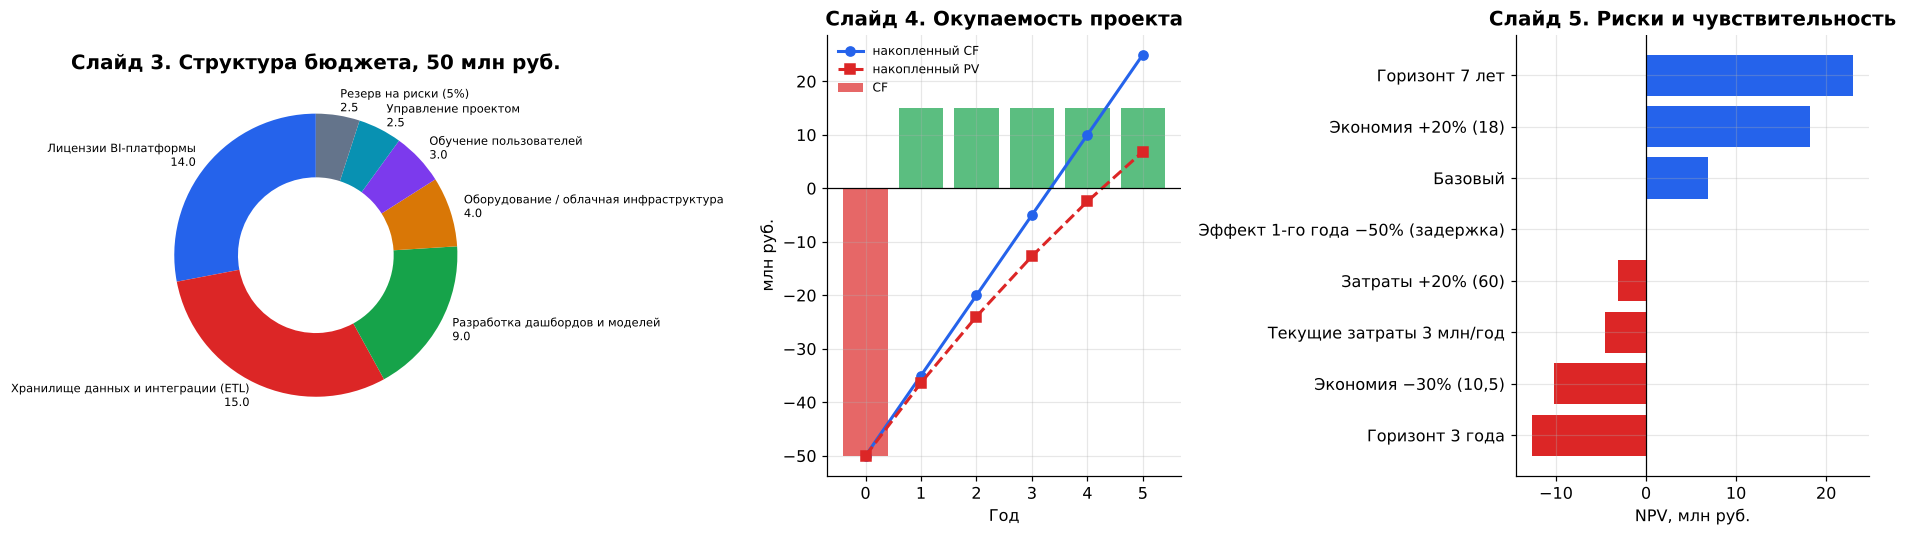

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
ax.pie(budget.values, labels=[f"{k}\n{v:.1f}" for k, v in budget.items()], startangle=90, colors=PALETTE + ["#94a3b8"],
       wedgeprops=dict(width=0.45), textprops=dict(fontsize=7.5))
ax.set_title("Слайд 3. Структура бюджета, 50 млн руб.")
ax = axes[1]
ax.bar(tbl["Год"], tbl["CF"], color=[PALETTE[1]] + [PALETTE[2]] * H, alpha=0.7, label="CF")
ax.plot(tbl["Год"], tbl["Накопл. CF"], "o-", lw=2, label="накопленный CF")
ax.plot(tbl["Год"], tbl["Накопл. PV"], "s--", lw=2, label="накопленный PV")
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("Год"); ax.set_ylabel("млн руб.")
ax.set_title("Слайд 4. Окупаемость проекта"); ax.legend(fontsize=8)
ax = axes[2]
s = sc.sort_values("NPV (10%)")
ax.barh(s.index, s["NPV (10%)"], color=[PALETTE[1] if v < 0 else PALETTE[0] for v in s["NPV (10%)"]])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("NPV, млн руб."); ax.set_title("Слайд 5. Риски и чувствительность")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **ROI за 5 лет 50 %**, **NPV около 6,9 млн руб.** при 10 %, **IRR около 15,2 %**, простой срок окупаемости **3,3 года**,
  дисконтированный **около 4,3 года**. Проект выгоден, но **запас небольшой**: безубыточная экономия около 13,2 млн руб. в год,
  то есть эффект может оказаться ниже плана всего на 12 %.
- Слабые места, о которых точно спросят: затраты на владение (при 3 млн руб. в год NPV уходит в минус),
  задержка эффекта в первый год, срок 3 года (проект не окупается), ставка 15 % (NPV около 0).
- Поэтому защищать бюджет надо не цифрой NPV, а **планом управления рисками**: подтверждённой экономией
  и финансированием по этапам.

### 6.1. Структура презентации (8 слайдов, 10 минут)
| № | Слайд | Содержание |
|---|---|---|
| 1 | Проблема | сколько сейчас стоят ручные отчёты (часы аналитиков, ошибки, медленные решения) |
| 2 | Решение | что даёт BI: одни данные для всех, дашборды, отчёты без очереди к ИТ |
| 3 | Бюджет 50 млн руб. | из чего состоит (диаграмма), сравнение с аналогами на рынке |
| 4 | Эффект | откуда 15 млн руб. экономии в год, ROI 50 %, NPV 6,9 млн, окупаемость 3,3 года |
| 5 | Риски и чувствительность | сценарии, порог безубыточности, что делаем с рисками |
| 6 | План внедрения | этапы, контрольные точки, быстрые результаты за первые 3 месяца |
| 7 | Управление и KPI | владелец проекта, метрики эффекта, отчётность |
| 8 | Что просим | одобрить этап 1 (пилот) и бюджет с условием перехода к этапу 2 |

## 7. Выводы и рекомендации

### 7.1. Аргументы для каждой стороны
| Сторона | Что ей важно | Аргумент |
|---|---|---|
| Финансовый директор | окупаемость, риски | NPV > 0, IRR 15 % выше ставки 10 %, окупаемость 3,3 года, этапы ограничивают возможные потери |
| Генеральный директор | стратегия, скорость решений | решения на свежих данных, все KPI на одном экране, преимущество перед конкурентами |
| Руководители подразделений | свои отчёты, время | на подготовку отчётов уходит на 30–40 % меньше времени, без очереди к ИТ |
| ИТ-директор | архитектура, нагрузка | одно хранилище вместо кучи выгрузок, стандарты данных, меньше ручных запросов |
| Аналитики | удобство, обучение | обучение в бюджете (3 млн руб.), меньше рутины, больше анализа |
| Служба безопасности | доступ к данным | доступ по ролям, журнал действий, данные внутри контура |

### 7.2. Как согласовать бюджет
1. **Деньги по этапам:** этап 1 пилот в одном подразделении (около 12 млн руб., 4 месяца). К этапу 2 переходим,
   только если пилот подтвердил хотя бы 70 % плановой экономии.
2. **Точка отсчёта:** до старта замерить, сколько сейчас уходит на отчёты, чтобы было с чем сравнить экономию.
3. **Общая ответственность:** включить экономию в KPI руководителей подразделений-заказчиков.
4. **Резерв у комитета** (2,5 млн руб.): тратится только по решению управляющего комитета.
5. **Проверка через год:** сравнить фактические ROI и экономию с планом и поправить бюджет следующих этапов.
6. **Варианты для торга:** облачная подписка вместо покупки лицензий (меньше денег на старте), отечественная платформа.